In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
print("Libraries loaded")

Libraries loaded


In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = list(uploaded.keys())[0]
except ImportError:
    DATA_PATH = "energy_efficiency_data.csv"
print("Data file:", DATA_PATH)

Saving energy_efficiency_data (2).csv to energy_efficiency_data (2).csv
Data file: energy_efficiency_data (2).csv


In [ ]:
OUT_DIR = "eda_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

FEATURES = [
    "Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area",
    "Overall_Height", "Orientation", "Glazing_Area", "Glazing_Area_Distribution",
]
TARGETS = ["Heating_Load", "Cooling_Load"]   # Y1, Y2

def save_fig(name):
    path = os.path.join(OUT_DIR, name)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"saved -> {path}")

In [ ]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (768, 10)


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [ ]:
print("=== Info ===")
df.info()

print("\n=== Missing values ===")
missing = df.isnull().sum()
print(missing)
print("Total missing:", int(missing.sum()))

print("\n=== Duplicates ===")
n_dup = df.duplicated().sum()
print("Duplicate rows:", int(n_dup))
if n_dup > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("After dropping duplicates:", df.shape)

print("\n=== Unique values per column ===")
print(df.nunique())

print("\n=== Negative values per column ===")
print((df < 0).sum())

quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isnull().sum(),
    "unique": df.nunique(),
    "min": df.min(),
    "max": df.max(),
})
quality.to_csv(os.path.join(OUT_DIR, "data_quality_report.csv"))
quality

=== Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Relative_Compactness       768 non-null    float64
 1   Surface_Area               768 non-null    float64
 2   Wall_Area                  768 non-null    float64
 3   Roof_Area                  768 non-null    float64
 4   Overall_Height             768 non-null    float64
 5   Orientation                768 non-null    int64  
 6   Glazing_Area               768 non-null    float64
 7   Glazing_Area_Distribution  768 non-null    int64  
 8   Heating_Load               768 non-null    float64
 9   Cooling_Load               768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB

=== Missing values ===
Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Hei

,dtype,missing,unique,min,max
Relative_Compactness,float64,0,12,0.62,0.98
Surface_Area,float64,0,12,514.50,808.50
Wall_Area,float64,0,7,245.00,416.50
Roof_Area,float64,0,4,110.25,220.50
Overall_Height,float64,0,2,3.50,7.00
Orientation,int64,0,4,2.00,5.00
Glazing_Area,float64,0,4,0.00,0.40
Glazing_Area_Distribution,int64,0,6,0.00,5.00
Heating_Load,float64,0,586,6.01,43.10
Cooling_Load,float64,0,636,10.90,48.03


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Relative_Compactness,768.0,0.764167,0.105777,0.62,0.6825,0.75,0.8300,0.98
Surface_Area,768.0,671.708333,88.086116,514.50,606.3750,673.75,741.1250,808.50
Wall_Area,768.0,318.500000,43.626481,245.00,294.0000,318.50,343.0000,416.50
Roof_Area,768.0,176.604167,45.165950,110.25,140.8750,183.75,220.5000,220.50
Overall_Height,768.0,5.250000,1.751140,3.50,3.5000,5.25,7.0000,7.00
Orientation,768.0,3.500000,1.118763,2.00,2.7500,3.50,4.2500,5.00
Glazing_Area,768.0,0.234375,0.133221,0.00,0.1000,0.25,0.4000,0.40
Glazing_Area_Distribution,768.0,2.812500,1.550960,0.00,1.7500,3.00,4.0000,5.00
Heating_Load,768.0,22.307201,10.090196,6.01,12.9925,18.95,31.6675,43.10
Cooling_Load,768.0,24.587760,9.513306,10.90,15.6200,22.08,33.1325,48.03


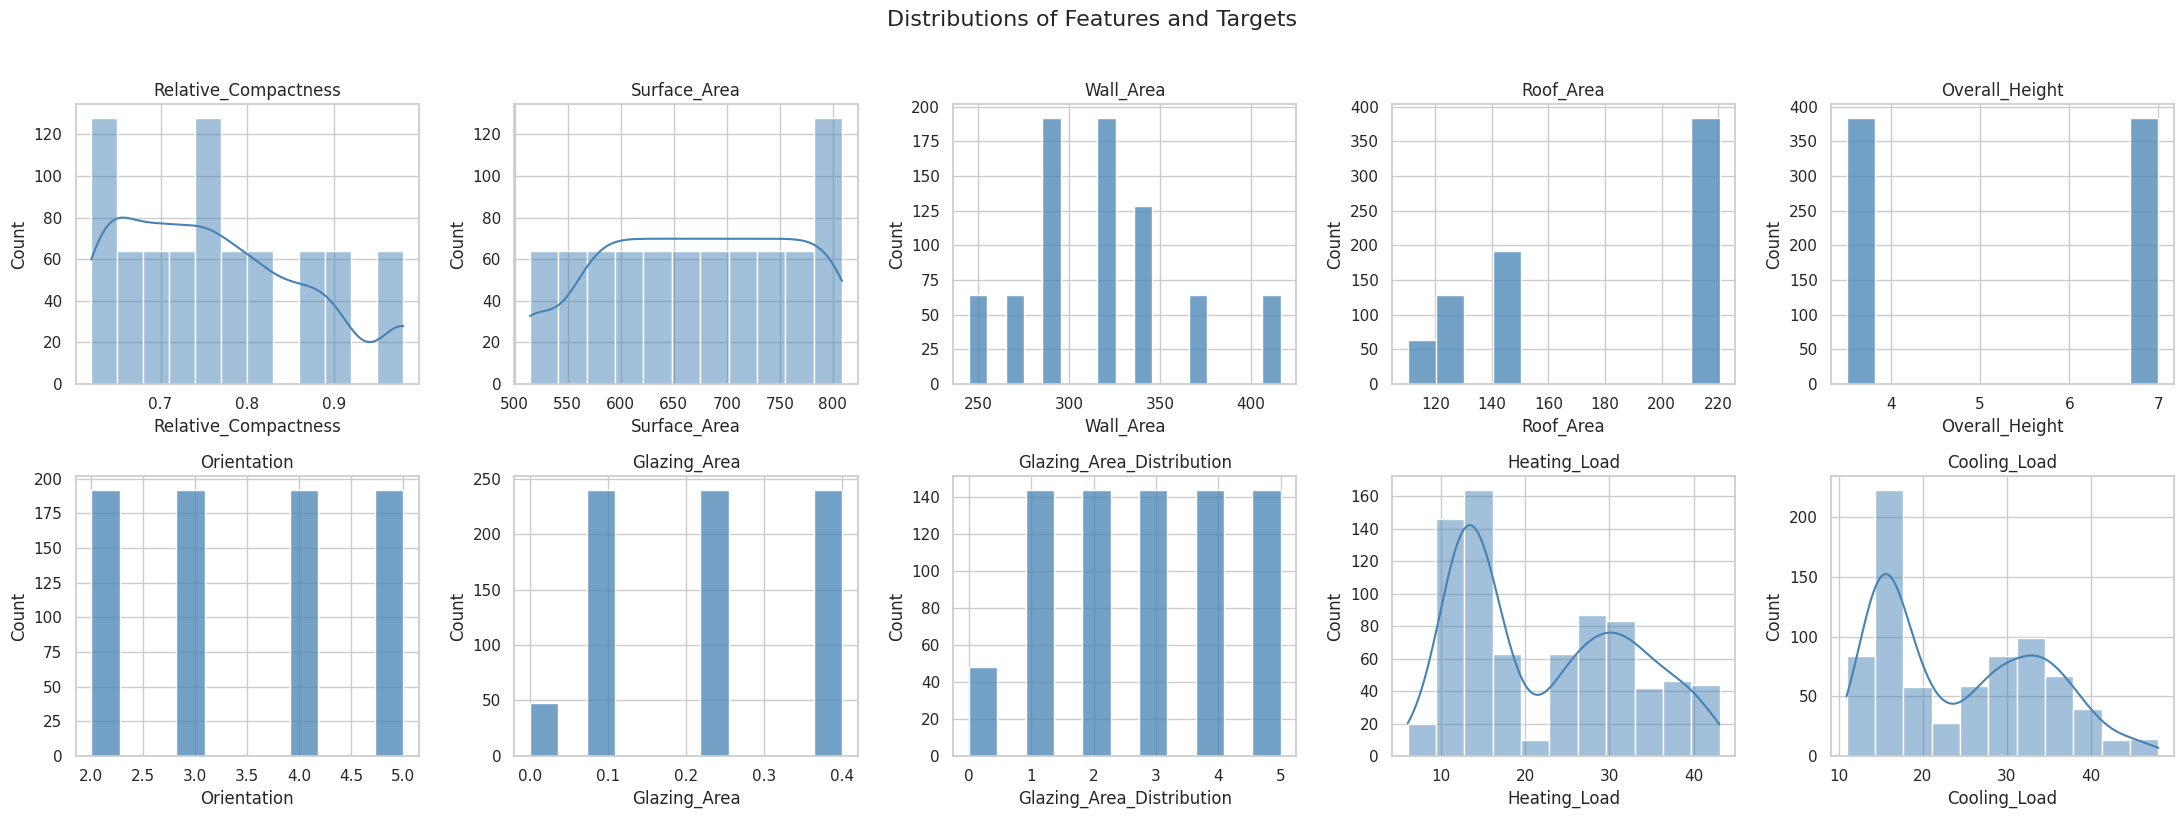

saved -> eda_outputs/01_distributions.png


In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.ravel(), FEATURES + TARGETS):
    sns.histplot(df[col], kde=(df[col].nunique() > 10), ax=ax, color="steelblue")
    ax.set_title(col)
plt.suptitle("Distributions of Features and Targets", fontsize=16, y=1.02)
save_fig("01_distributions.png")

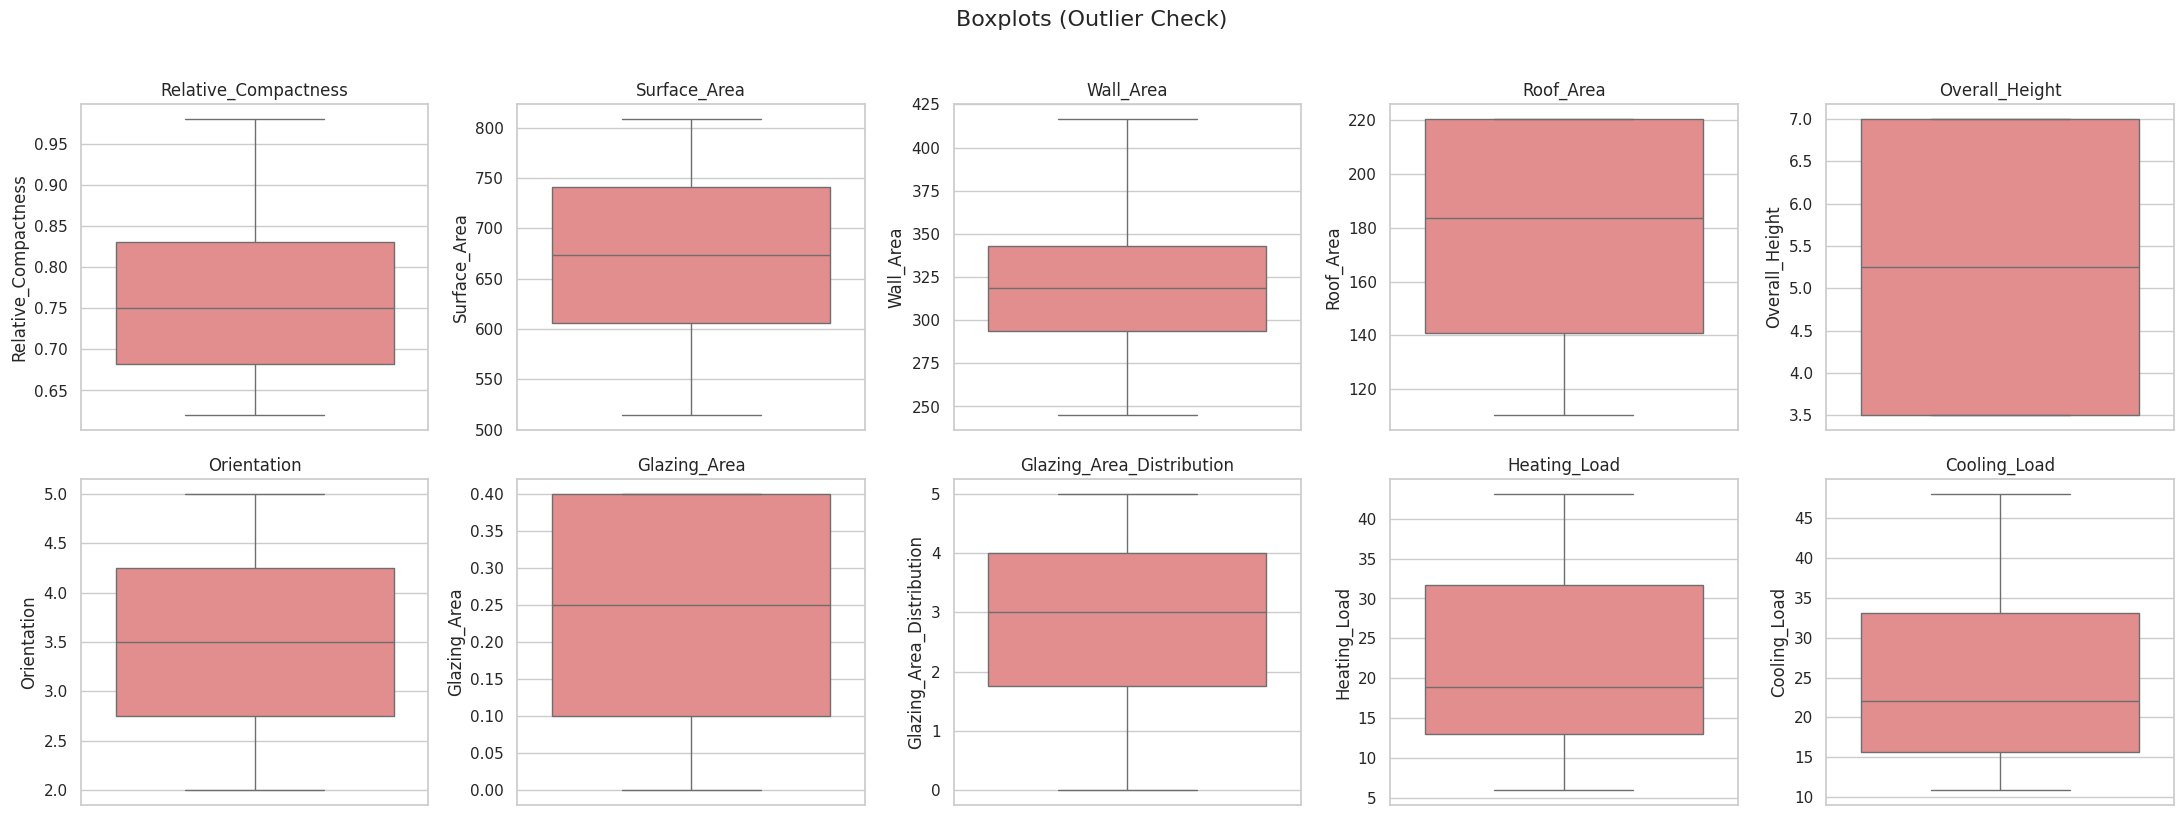

saved -> eda_outputs/02_boxplots.png
=== Outliers (IQR rule) ===
Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation                  0
Glazing_Area                 0
Glazing_Area_Distribution    0
Heating_Load                 0
Cooling_Load                 0


In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.ravel(), FEATURES + TARGETS):
    sns.boxplot(y=df[col], ax=ax, color="lightcoral")
    ax.set_title(col)
plt.suptitle("Boxplots (Outlier Check)", fontsize=16, y=1.02)
save_fig("02_boxplots.png")

print("=== Outliers (IQR rule) ===")
for col in df.columns:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:28s} {int(n_out)}")

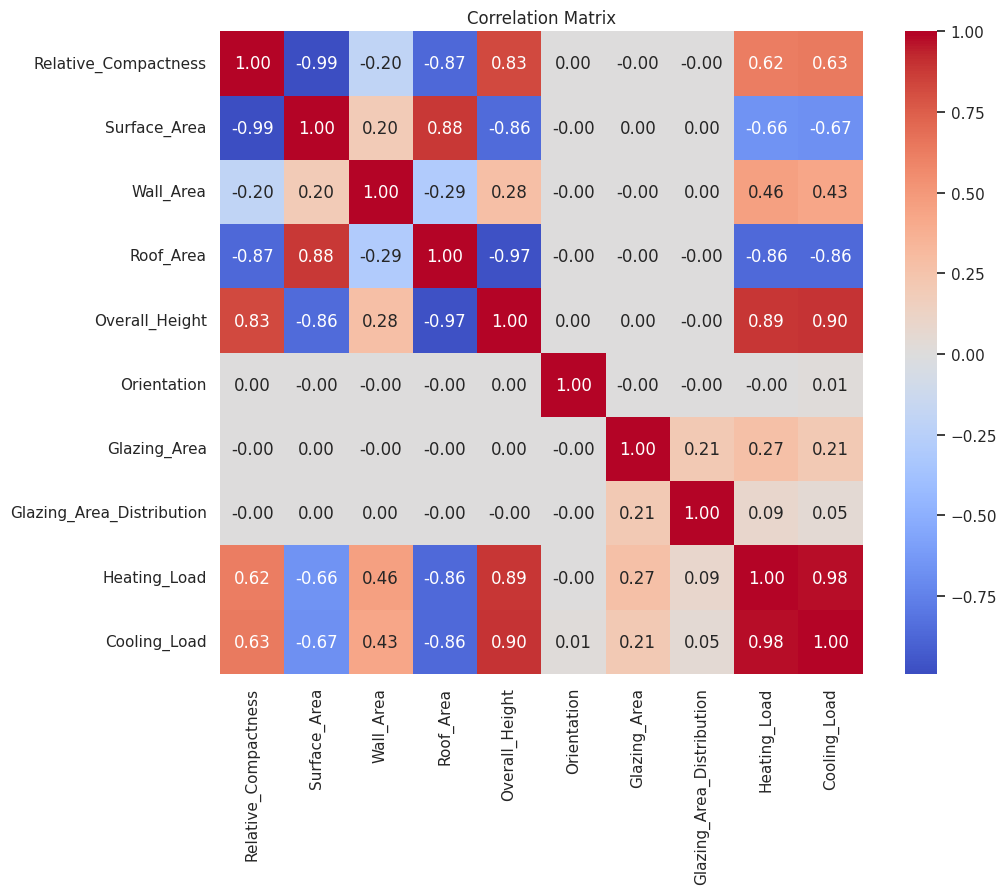

saved -> eda_outputs/03_correlation_heatmap.png
=== Correlation with targets ===


,Heating_Load,Cooling_Load
Overall_Height,0.889431,0.895785
Relative_Compactness,0.622272,0.634339
Wall_Area,0.455671,0.427117
Glazing_Area,0.269841,0.207505
Glazing_Area_Distribution,0.087368,0.050525
Orientation,-0.002587,0.014290
Surface_Area,-0.658120,-0.672999
Roof_Area,-0.861828,-0.862547


In [ ]:
corr = df.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix")
save_fig("03_correlation_heatmap.png")

print("=== Correlation with targets ===")
corr[TARGETS].drop(TARGETS).sort_values("Heating_Load", ascending=False)

In [ ]:
feat_corr = df[FEATURES].corr().abs()
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool))
high = (
    upper.stack().reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "abs_corr"})
    .query("abs_corr > 0.8")
    .sort_values("abs_corr", ascending=False)
)
print("=== Feature pairs with |corr| > 0.8 ===")
high

=== Feature pairs with |corr| > 0.8 ===


,feature_1,feature_2,abs_corr
0,Relative_Compactness,Surface_Area,0.991901
18,Roof_Area,Overall_Height,0.972512
8,Surface_Area,Roof_Area,0.880720
2,Relative_Compactness,Roof_Area,0.868823
9,Surface_Area,Overall_Height,0.858148
3,Relative_Compactness,Overall_Height,0.827747


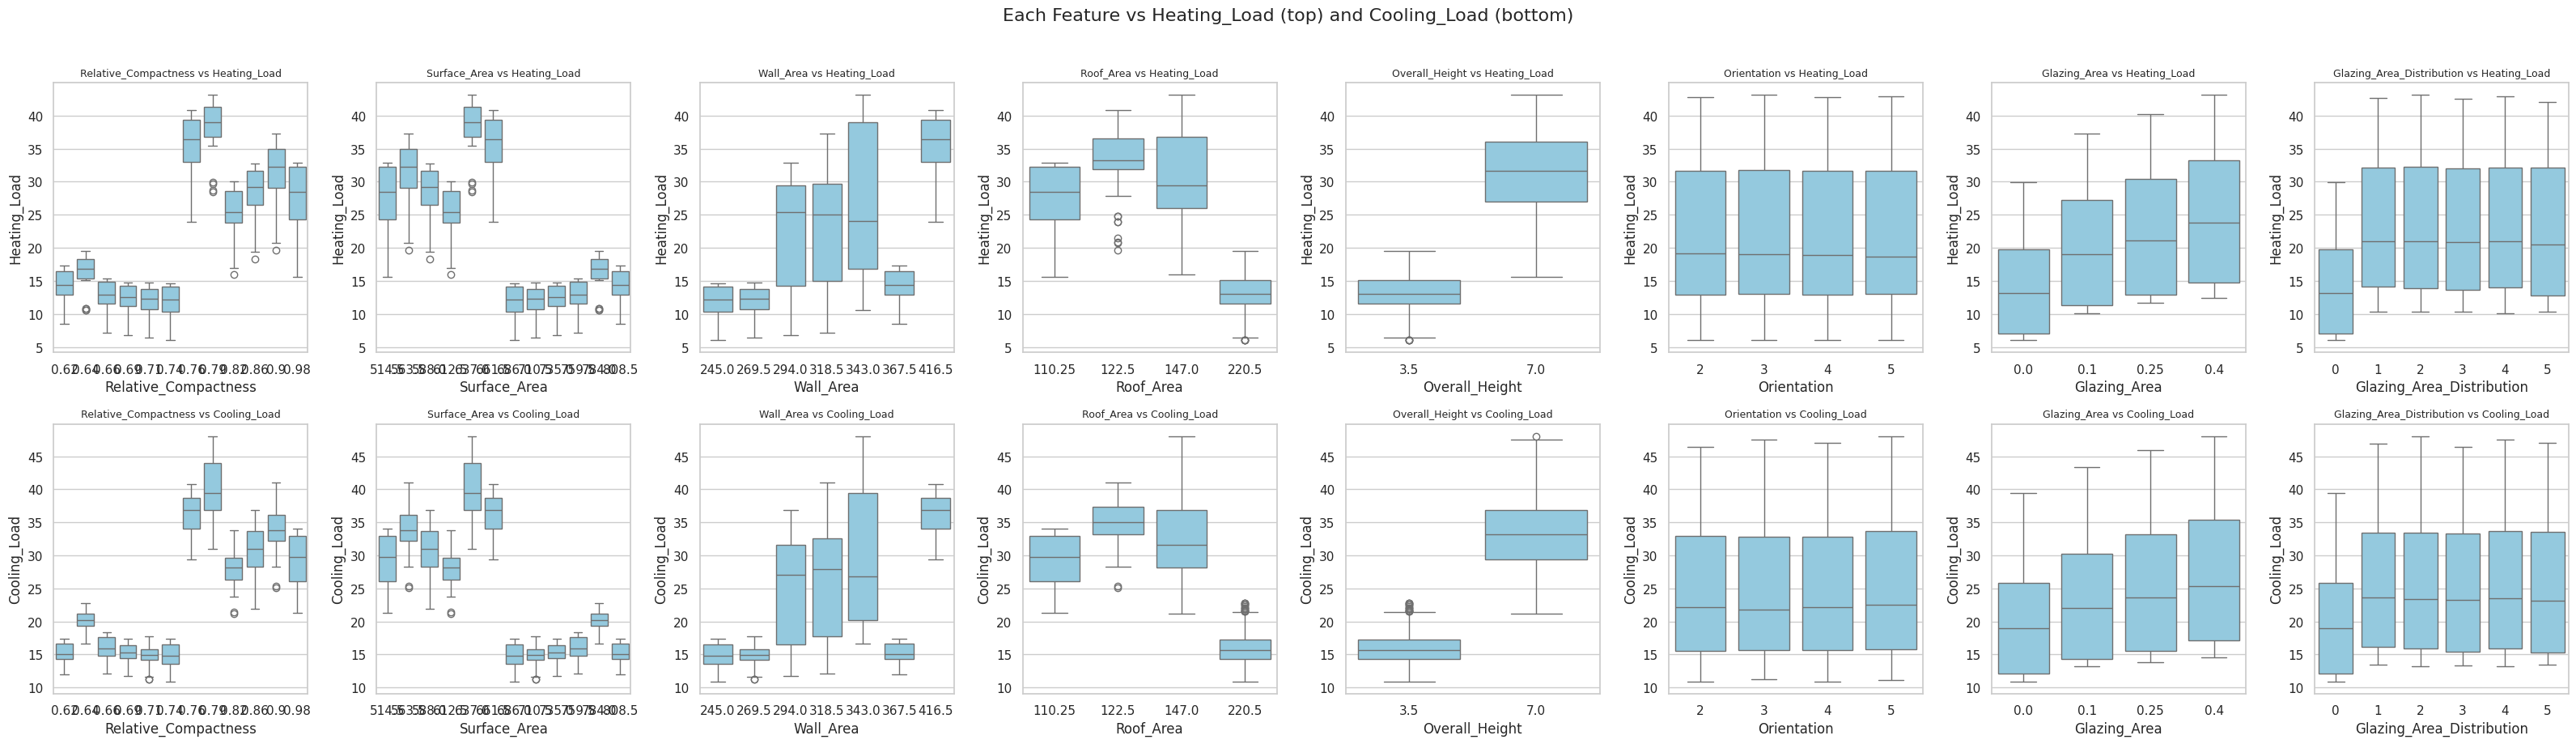

saved -> eda_outputs/04_features_vs_targets.png


In [ ]:
fig, axes = plt.subplots(2, 8, figsize=(32, 9))
for j, col in enumerate(FEATURES):
    for i, tgt in enumerate(TARGETS):
        ax = axes[i, j]
        if df[col].nunique() <= 12:
            sns.boxplot(x=df[col], y=df[tgt], ax=ax, color="skyblue")
        else:
            sns.scatterplot(x=df[col], y=df[tgt], ax=ax, alpha=0.5)
        ax.set_title(f"{col} vs {tgt}", fontsize=9)
plt.suptitle("Each Feature vs Heating_Load (top) and Cooling_Load (bottom)", fontsize=16, y=1.02)
save_fig("04_features_vs_targets.png")

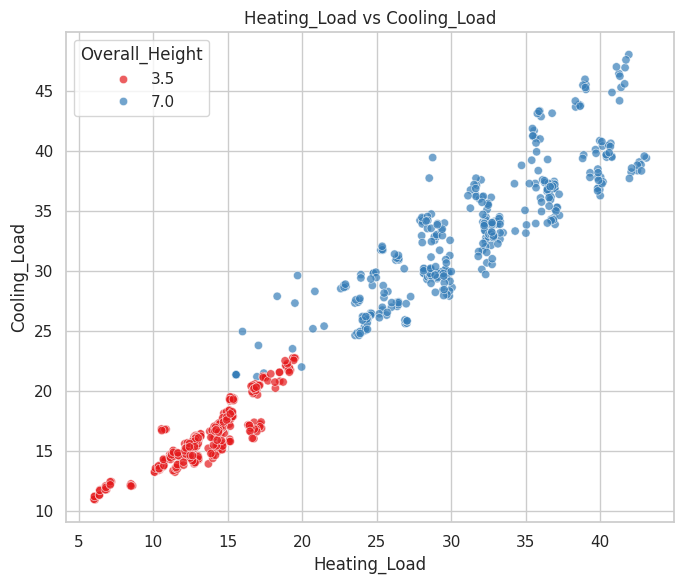

saved -> eda_outputs/05_heating_vs_cooling.png
Corr(Y1, Y2) = 0.976


In [ ]:
plt.figure(figsize=(7, 6))
sns.scatterplot(data=df, x="Heating_Load", y="Cooling_Load",
                hue="Overall_Height", palette="Set1", alpha=0.7)
plt.title("Heating_Load vs Cooling_Load")
save_fig("05_heating_vs_cooling.png")
print("Corr(Y1, Y2) =", round(df["Heating_Load"].corr(df["Cooling_Load"]), 3))

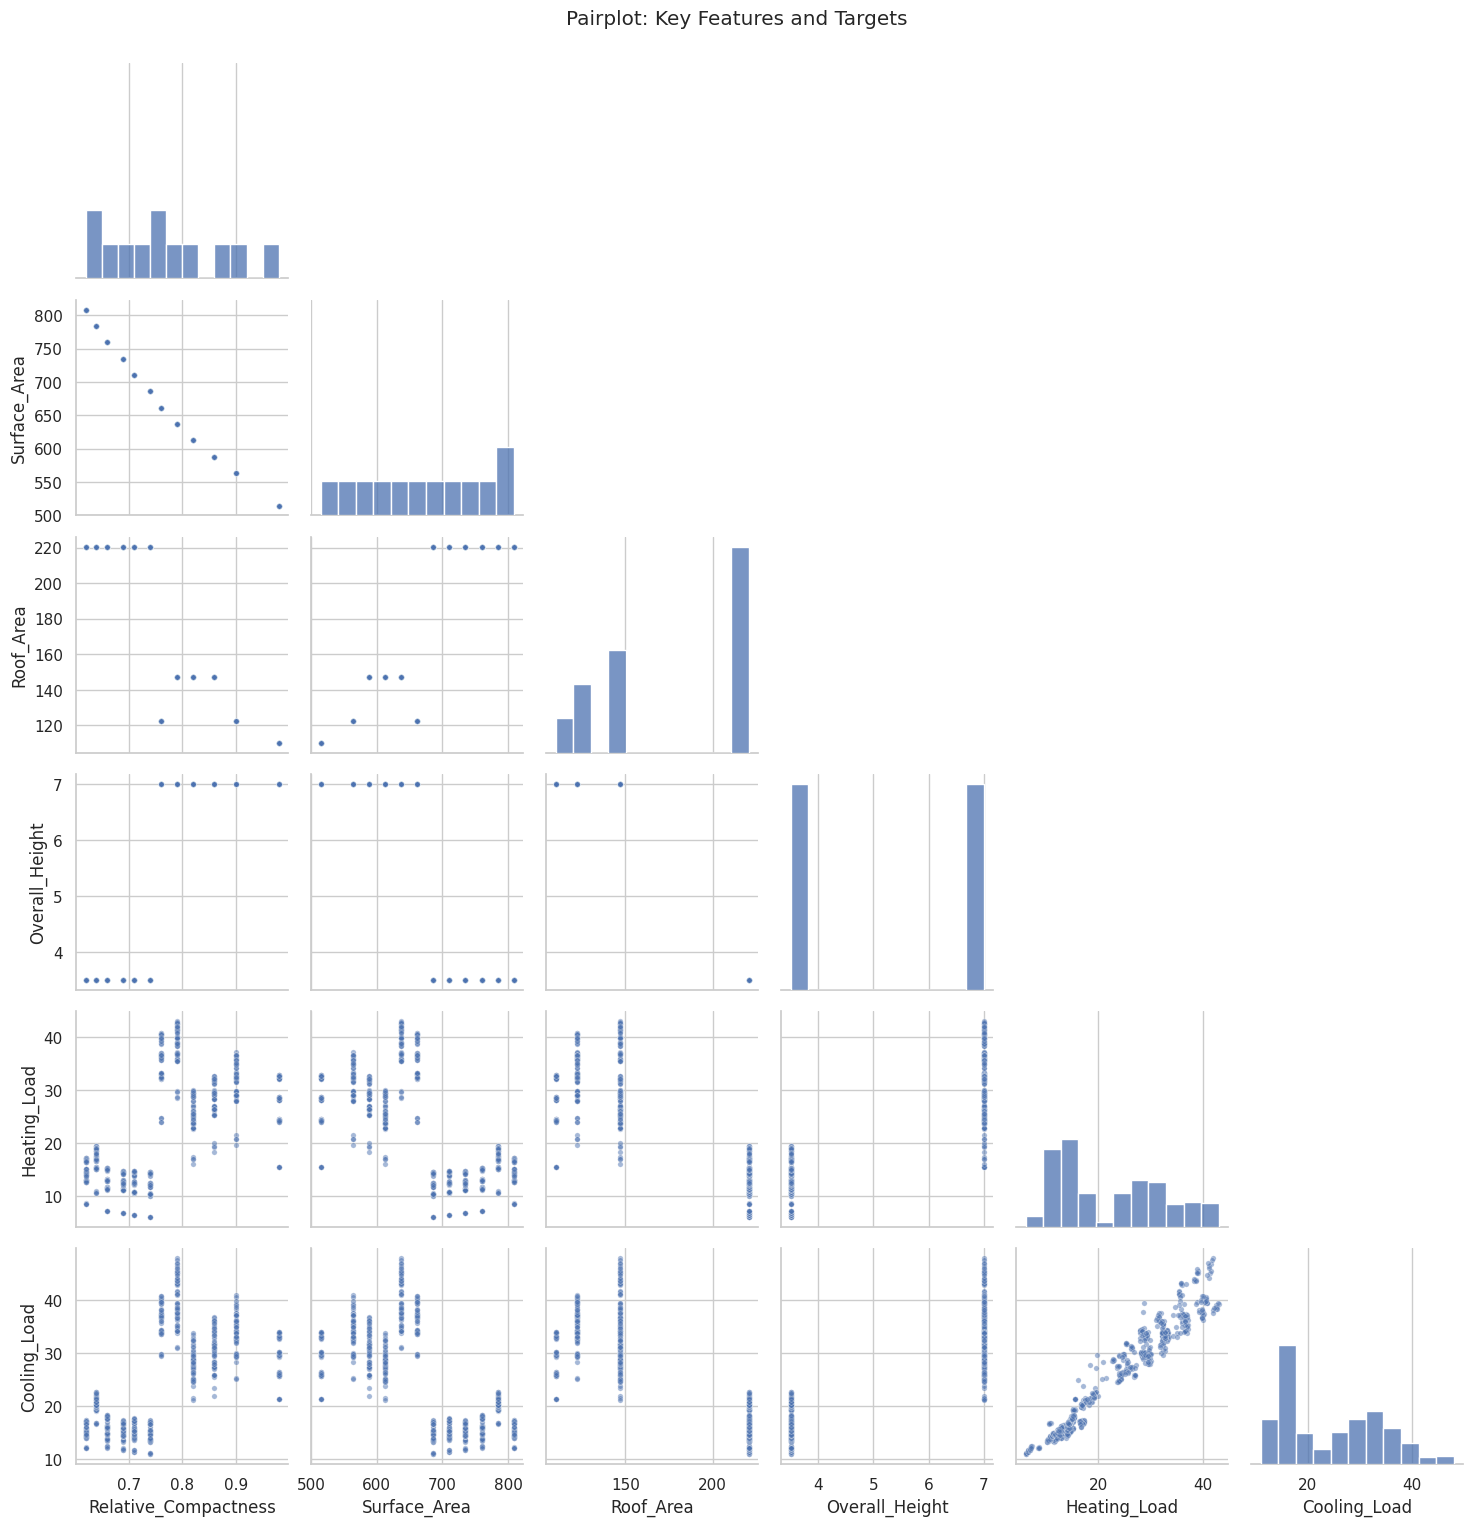

In [ ]:
top_feats = ["Relative_Compactness", "Surface_Area", "Roof_Area", "Overall_Height"]
g = sns.pairplot(df[top_feats + TARGETS], corner=True, plot_kws={"alpha": 0.5, "s": 15})
g.fig.suptitle("Pairplot: Key Features and Targets", y=1.02)
g.savefig(os.path.join(OUT_DIR, "06_pairplot.png"), dpi=120, bbox_inches="tight")
plt.show()
plt.close()

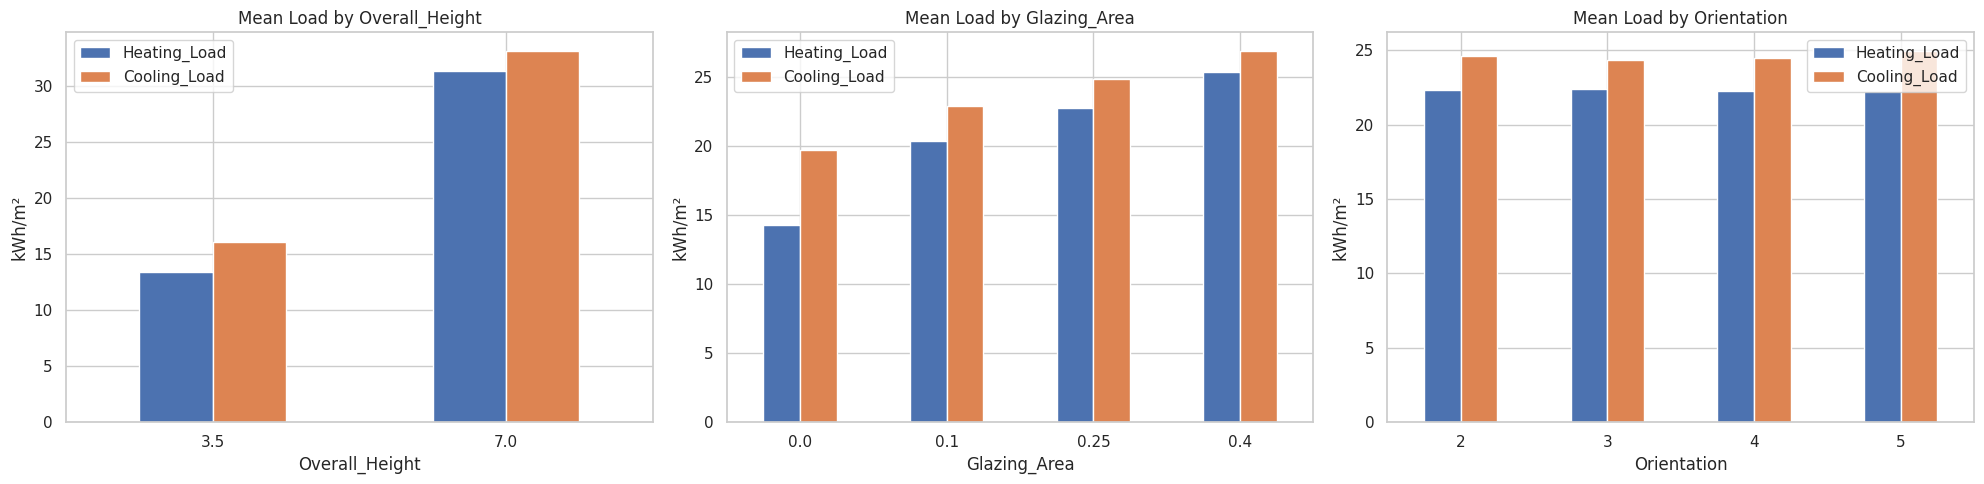

saved -> eda_outputs/07_mean_load_by_category.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, col in zip(axes, ["Overall_Height", "Glazing_Area", "Orientation"]):
    df.groupby(col)[TARGETS].mean().plot(kind="bar", ax=ax)
    ax.set_title(f"Mean Load by {col}")
    ax.set_ylabel("kWh/m²")
    ax.tick_params(axis="x", rotation=0)
save_fig("07_mean_load_by_category.png")

In [ ]:
best_h = corr["Heating_Load"].drop(TARGETS).abs().idxmax()
best_c = corr["Cooling_Load"].drop(TARGETS).abs().idxmax()

summary = f'''
===== EDA SUMMARY =====
Rows: {df.shape[0]} | Columns: {df.shape[1]}
Missing values: {int(df.isnull().sum().sum())}
Duplicate rows: {int(df.duplicated().sum())}
Problem type: Regression (2 targets: Heating_Load, Cooling_Load)

Strongest feature vs Heating_Load: {best_h} (corr={corr.loc[best_h, 'Heating_Load']:.2f})
Strongest feature vs Cooling_Load: {best_c} (corr={corr.loc[best_c, 'Cooling_Load']:.2f})
Corr(Heating, Cooling): {df['Heating_Load'].corr(df['Cooling_Load']):.2f}

Notes for the team:
- Dataset is clean (no missing, no duplicates, no outliers).
- Surface_Area / Relative_Compactness / Roof_Area are highly correlated (multicollinearity)
  -> matters for Linear Regression; tree models handle it fine.
- Orientation & Glazing_Area_Distribution are categorical-like with very weak correlation to targets.
- Overall_Height and Roof_Area have the strongest relation with the loads.
'''
print(summary)
with open(os.path.join(OUT_DIR, "eda_summary.txt"), "w", encoding="utf-8") as f:
    f.write(summary)


===== EDA SUMMARY =====
Rows: 768 | Columns: 10
Missing values: 0
Duplicate rows: 0
Problem type: Regression (2 targets: Heating_Load, Cooling_Load)

Strongest feature vs Heating_Load: Overall_Height (corr=0.89)
Strongest feature vs Cooling_Load: Overall_Height (corr=0.90)
Corr(Heating, Cooling): 0.98

Notes for the team:
- Dataset is clean (no missing, no duplicates, no outliers).
- Surface_Area / Relative_Compactness / Roof_Area are highly correlated (multicollinearity)
  -> matters for Linear Regression; tree models handle it fine.
- Orientation & Glazing_Area_Distribution are categorical-like with very weak correlation to targets.
- Overall_Height and Roof_Area have the strongest relation with the loads.



2️⃣ Preprocessing & Feature Engineering

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
import joblib

CAT_COLS = ["Orientation", "Glazing_Area_Distribution"]

X = df[FEATURES]
y = df[TARGETS]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (614, 8) | Test: (154, 8)


In [ ]:
def add_features(X, engineer=True, drop=()):
    X = X.copy()
    if engineer:
        X["Wall_Surface_Ratio"] = X["Wall_Area"] / X["Surface_Area"]
        X["Glazing_x_Height"] = X["Glazing_Area"] * X["Overall_Height"]
    return X.drop(columns=list(drop))

def build_preprocessor(scale=True, onehot=True, engineer=True, drop=()):
    num_cols = [c for c in FEATURES if c not in CAT_COLS and c not in drop]
    if engineer:
        num_cols += ["Wall_Surface_Ratio", "Glazing_x_Height"]

    num_tf = StandardScaler() if scale else "passthrough"
    cat_tf = OneHotEncoder(handle_unknown="ignore", sparse_output=False) if onehot else "passthrough"

    ct = ColumnTransformer([
        ("num", num_tf, num_cols),
        ("cat", cat_tf, CAT_COLS),
    ])
    return Pipeline([
        ("features", FunctionTransformer(add_features,
                                         kw_args={"engineer": engineer, "drop": drop})),
        ("transform", ct),
    ])

# نسخة للموديلات الخطية (scaling + onehot) ونسخة للـ trees (من غير scaling)
prep_linear = build_preprocessor(scale=True, onehot=True)
prep_tree   = build_preprocessor(scale=False, onehot=False)

Xtr_lin = prep_linear.fit_transform(X_train)   # fit على الـ train بس
Xte_lin = prep_linear.transform(X_test)
print("Linear-ready shape:", Xtr_lin.shape)

Linear-ready shape: (614, 18)


In [ ]:
experiments = {
    "Baseline (original features)":      dict(engineer=False),
    "+ New features":                    dict(engineer=True),
    "Drop Surface_Area":                 dict(engineer=False, drop=("Surface_Area",)),
    "Drop Surface_Area + Roof_Area":     dict(engineer=False, drop=("Surface_Area", "Roof_Area")),
    "New features + drop Surface_Area":  dict(engineer=True,  drop=("Surface_Area",)),
}

rows = []
for name, cfg in experiments.items():
    pipe = Pipeline([
        ("prep", build_preprocessor(scale=True, onehot=True, **cfg)),
        ("model", LinearRegression()),
    ])
    r2 = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2")
    rmse = -cross_val_score(pipe, X_train, y_train, cv=5,
                            scoring="neg_root_mean_squared_error")
    rows.append({"Experiment": name, "CV R²": r2.mean().round(4), "CV RMSE": rmse.mean().round(3)})

exp_df = pd.DataFrame(rows).sort_values("CV R²", ascending=False)
exp_df.to_csv(os.path.join(OUT_DIR, "feature_experiments.csv"), index=False)
exp_df

,Experiment,CV R²,CV RMSE
1,+ New features,0.9083,2.921
4,New features + drop Surface_Area,0.9083,2.921
0,Baseline (original features),0.9019,3.029
2,Drop Surface_Area,0.9019,3.029
3,Drop Surface_Area + Roof_Area,0.8987,3.077


In [ ]:
os.makedirs("processed", exist_ok=True)

X_train.assign(**y_train).to_csv("processed/train.csv", index=False)
X_test.assign(**y_test).to_csv("processed/test.csv", index=False)
joblib.dump(prep_linear, "processed/preprocessor_linear.joblib")
joblib.dump(prep_tree,   "processed/preprocessor_tree.joblib")
print("saved")

saved


In [ ]:
import os
os.makedirs("src", exist_ok=True)
open("src/__init__.py", "w").close()

code = '''
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

FEATURES = [
    "Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area",
    "Overall_Height", "Orientation", "Glazing_Area", "Glazing_Area_Distribution",
]
TARGETS = ["Heating_Load", "Cooling_Load"]
CAT_COLS = ["Orientation", "Glazing_Area_Distribution"]

def add_features(X, engineer=True, drop=()):
    X = X.copy()
    if engineer:
        X["Wall_Surface_Ratio"] = X["Wall_Area"] / X["Surface_Area"]
        X["Glazing_x_Height"] = X["Glazing_Area"] * X["Overall_Height"]
    return X.drop(columns=list(drop))

def build_preprocessor(scale=True, onehot=True, engineer=True, drop=()):
    num_cols = [c for c in FEATURES if c not in CAT_COLS and c not in drop]
    if engineer:
        num_cols += ["Wall_Surface_Ratio", "Glazing_x_Height"]
    num_tf = StandardScaler() if scale else "passthrough"
    cat_tf = OneHotEncoder(handle_unknown="ignore", sparse_output=False) if onehot else "passthrough"
    ct = ColumnTransformer([("num", num_tf, num_cols), ("cat", cat_tf, CAT_COLS)])
    return Pipeline([
        ("features", FunctionTransformer(add_features, kw_args={"engineer": engineer, "drop": drop})),
        ("transform", ct),
    ])
'''
with open("src/preprocessing.py", "w") as f:
    f.write(code)

print(os.listdir("src"))

['preprocessing.py', '__init__.py']


In [ ]:
import joblib
from src.preprocessing import build_preprocessor, FEATURES, TARGETS

prep_linear = build_preprocessor(scale=True, onehot=True)
prep_tree   = build_preprocessor(scale=False, onehot=False)
prep_linear.fit(X_train)
prep_tree.fit(X_train)

os.makedirs("processed", exist_ok=True)
X_train.assign(**y_train).to_csv("processed/train.csv", index=False)
X_test.assign(**y_test).to_csv("processed/test.csv", index=False)
joblib.dump(prep_linear, "processed/preprocessor_linear.joblib")
joblib.dump(prep_tree,   "processed/preprocessor_tree.joblib")

print(joblib.load("processed/preprocessor_linear.joblib").transform(X_test).shape)

(154, 18)


3️⃣ Modeling الأساسي (SageMaker Notebook)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

models = {
    "Linear Regression": (LinearRegression(), prep_linear),
    "Decision Tree":     (DecisionTreeRegressor(max_depth=8, random_state=42), prep_tree),
    "Random Forest":     (RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), prep_tree),
}

rows, preds = [], {}
for name, (model, prep) in models.items():
    model.fit(prep.transform(X_train), y_train)
    pred = model.predict(prep.transform(X_test))
    preds[name] = pred
    for i, tgt in enumerate(TARGETS):
        rows.append({
            "Model": name, "Target": tgt,
            "MAE":  mean_absolute_error(y_test[tgt], pred[:, i]),
            "RMSE": np.sqrt(mean_squared_error(y_test[tgt], pred[:, i])),
            "R²":   r2_score(y_test[tgt], pred[:, i]),
        })

results = pd.DataFrame(rows).round(4)
results.to_csv(os.path.join(OUT_DIR, "basic_models_results.csv"), index=False)
results

,Model,Target,MAE,RMSE,R²
0,Linear Regression,Heating_Load,1.8728,2.8002,0.9248
1,Linear Regression,Cooling_Load,2.1165,3.0471,0.8998
2,Decision Tree,Heating_Load,0.4071,0.5873,0.9967
3,Decision Tree,Cooling_Load,1.3253,2.2609,0.9448
4,Random Forest,Heating_Load,0.3446,0.4919,0.9977
5,Random Forest,Cooling_Load,1.1659,1.9043,0.9609


In [ ]:
cv_rows = []
for name, (model, prep) in models.items():
    pipe = Pipeline([("prep", prep), ("model", model)])
    for tgt in TARGETS:
        s = cross_val_score(pipe, X_train, y_train[tgt], cv=5, scoring="r2")
        cv_rows.append({"Model": name, "Target": tgt,
                        "CV R² mean": s.mean().round(4), "CV R² std": s.std().round(4)})
pd.DataFrame(cv_rows)

,Model,Target,CV R² mean,CV R² std
0,Linear Regression,Heating_Load,0.9275,0.0079
1,Linear Regression,Cooling_Load,0.8890,0.0124
2,Decision Tree,Heating_Load,0.9970,0.0003
3,Decision Tree,Cooling_Load,0.9595,0.0057
4,Random Forest,Heating_Load,0.9974,0.0005
5,Random Forest,Cooling_Load,0.9686,0.0052


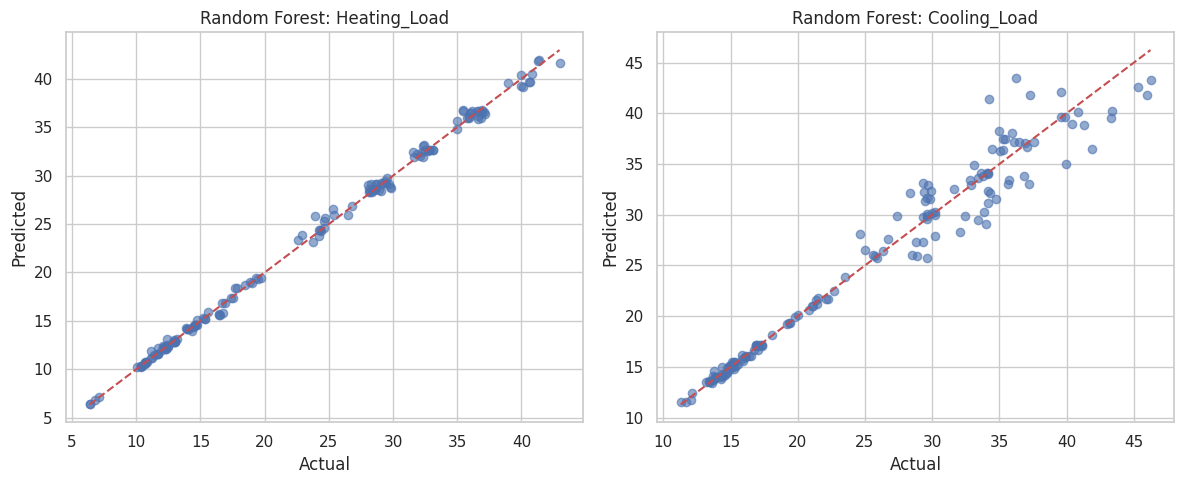

saved -> eda_outputs/08_actual_vs_pred.png


In [ ]:
best = "Random Forest"
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, (ax, tgt) in enumerate(zip(axes, TARGETS)):
    ax.scatter(y_test[tgt], preds[best][:, i], alpha=0.6)
    lims = [y_test[tgt].min(), y_test[tgt].max()]
    ax.plot(lims, lims, "r--")
    ax.set_xlabel("Actual"); ax.set_ylabel("Predicted"); ax.set_title(f"{best}: {tgt}")
save_fig("08_actual_vs_pred.png")

os.makedirs("models", exist_ok=True)
for name, (model, prep) in models.items():
    joblib.dump(model, f"models/{name.replace(' ', '_').lower()}.joblib")

رقم 4: Advanced Models & Tuning

In [ ]:
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

adv_models = {
    "Gradient Boosting": MultiOutputRegressor(GradientBoostingRegressor(random_state=42)),
    "XGBoost": MultiOutputRegressor(XGBRegressor(random_state=42, n_jobs=-1, verbosity=0)),
}

rows = []
for name, model in adv_models.items():
    model.fit(prep_tree.transform(X_train), y_train)
    pred = model.predict(prep_tree.transform(X_test))
    preds[name] = pred
    for i, tgt in enumerate(TARGETS):
        rows.append({"Model": name, "Target": tgt,
                     "MAE": mean_absolute_error(y_test[tgt], pred[:, i]),
                     "RMSE": np.sqrt(mean_squared_error(y_test[tgt], pred[:, i])),
                     "R²": r2_score(y_test[tgt], pred[:, i])})
pd.DataFrame(rows).round(4)

,Model,Target,MAE,RMSE,R²
0,Gradient Boosting,Heating_Load,0.3890,0.5212,0.9974
1,Gradient Boosting,Cooling_Load,1.0075,1.4619,0.9769
2,XGBoost,Heating_Load,0.2731,0.4226,0.9983
3,XGBoost,Cooling_Load,0.4962,1.0150,0.9889


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [200, 400, 600, 800],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "min_child_weight": [1, 3, 5],
}

Xtr_t, Xte_t = prep_tree.transform(X_train), prep_tree.transform(X_test)
best_xgb, tuned_rows = {}, []
for tgt in TARGETS:
    search = RandomizedSearchCV(
        XGBRegressor(random_state=42, n_jobs=-1, verbosity=0),
        param_dist, n_iter=30, cv=5, scoring="r2", random_state=42, n_jobs=-1)
    search.fit(Xtr_t, y_train[tgt])
    best_xgb[tgt] = search.best_estimator_
    p = search.best_estimator_.predict(Xte_t)
    print(tgt, "best params:", search.best_params_)
    tuned_rows.append({"Target": tgt, "CV R²": round(search.best_score_, 4),
                       "Test MAE": mean_absolute_error(y_test[tgt], p),
                       "Test RMSE": np.sqrt(mean_squared_error(y_test[tgt], p)),
                       "Test R²": r2_score(y_test[tgt], p)})
tuned = pd.DataFrame(tuned_rows).round(4)
tuned.to_csv(os.path.join(OUT_DIR, "tuned_xgb_results.csv"), index=False)
tuned

Heating_Load best params: {'subsample': 0.7, 'n_estimators': 800, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.7}
Cooling_Load best params: {'subsample': 1.0, 'n_estimators': 600, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.7}


,Target,CV R²,Test MAE,Test RMSE,Test R²
0,Heating_Load,0.9986,0.2757,0.4177,0.9983
1,Cooling_Load,0.9892,0.4124,0.7319,0.9942


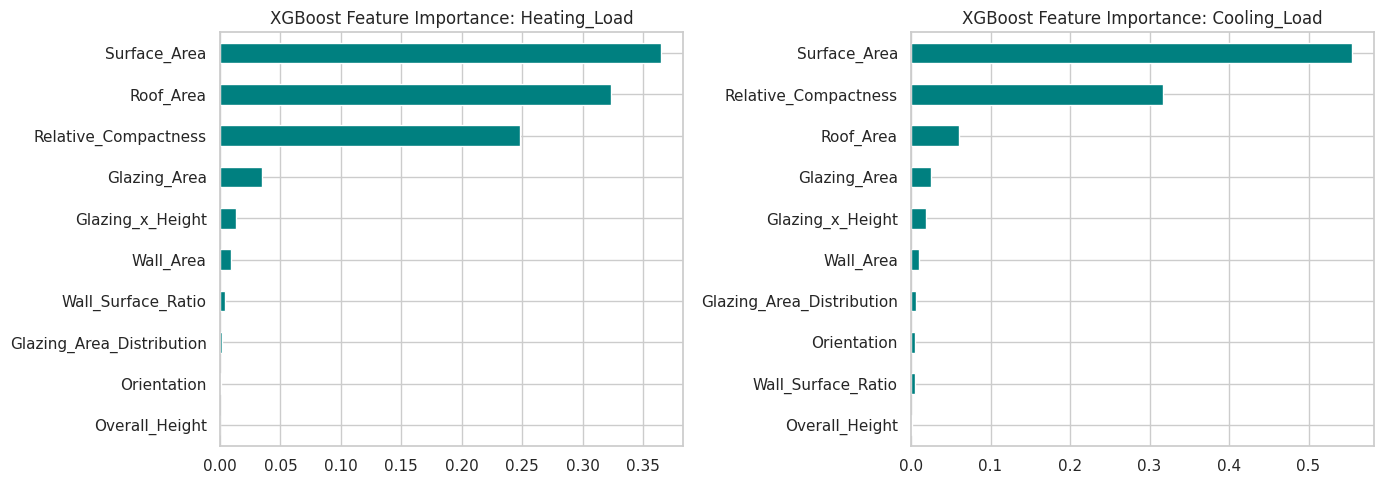

saved -> eda_outputs/09_feature_importance.png


In [ ]:
names = [n.split("__")[-1] for n in prep_tree.named_steps["transform"].get_feature_names_out()]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, tgt in zip(axes, TARGETS):
    imp = pd.Series(best_xgb[tgt].feature_importances_, index=names).sort_values()
    imp.plot(kind="barh", ax=ax, color="teal")
    ax.set_title(f"XGBoost Feature Importance: {tgt}")
save_fig("09_feature_importance.png")

for tgt in TARGETS:
    joblib.dump(best_xgb[tgt], f"models/xgb_{tgt.lower()}.joblib")

In [ ]:
import shutil
from google.colab import files

for d in ["src", "processed", "models", "eda_outputs", "app"]:
    if not os.path.exists(d):
        print("missing:", d)

shutil.make_archive("energy_project_outputs", "zip", ".", "src")  # مثال سريع
!zip -r energy_project_outputs.zip src processed models eda_outputs app
files.download("energy_project_outputs.zip")

missing: app
	zip warning: name not matched: app
updating: src/ (stored 0%)
updating: src/__pycache__/ (stored 0%)
updating: src/preprocessing.py (deflated 56%)
updating: src/__init__.py (stored 0%)
updating: src/__pycache__/preprocessing.cpython-313.pyc (deflated 33%)
updating: src/__pycache__/__init__.cpython-313.pyc (deflated 25%)
  adding: processed/ (stored 0%)
  adding: processed/preprocessor_linear.joblib (deflated 57%)
  adding: processed/preprocessor_tree.joblib (deflated 62%)
  adding: processed/train.csv (deflated 81%)
  adding: processed/test.csv (deflated 77%)
  adding: models/ (stored 0%)
  adding: models/decision_tree.joblib (deflated 72%)
  adding: models/xgb_heating_load.joblib (deflated 77%)
  adding: models/xgb_cooling_load.joblib (deflated 74%)
  adding: models/random_forest.joblib (deflated 77%)
  adding: models/linear_regression.joblib (deflated 12%)
  adding: eda_outputs/ (stored 0%)
  adding: eda_outputs/eda_summary.txt (deflated 42%)
  adding: eda_outputs/01_di

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
open("requirements.txt", "w").write("""pandas
numpy
scikit-learn
xgboost
joblib
matplotlib
seaborn
streamlit
""")

70

In [ ]:
%%writefile app.py
import joblib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import gradio as gr

FEATURES = [
    "Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area",
    "Overall_Height", "Orientation", "Glazing_Area", "Glazing_Area_Distribution",
]
GEO = ["Relative_Compactness", "Surface_Area", "Wall_Area", "Roof_Area", "Overall_Height"]

pre = joblib.load("processed/preprocessor_tree.joblib")
m_heat = joblib.load("models/xgb_heating_load.joblib")
m_cool = joblib.load("models/xgb_cooling_load.joblib")

data = pd.concat([pd.read_csv("processed/train.csv"), pd.read_csv("processed/test.csv")], ignore_index=True)
shapes = (data[GEO].drop_duplicates()
          .sort_values("Relative_Compactness", ascending=False).reset_index(drop=True))
AVG_H, AVG_C = data.Heating_Load.mean(), data.Cooling_Load.mean()
Q = (data.Heating_Load + data.Cooling_Load).quantile([.2, .4, .6, .8]).values
GRADES = ["A", "B", "C", "D", "E"]
COLORS = {"A": "#16a34a", "B": "#65a30d", "C": "#ca8a04", "D": "#ea580c", "E": "#dc2626"}


def grade(total):
    return GRADES[int(np.searchsorted(Q, total))]


def predict_batch(df_in):
    X = pre.transform(df_in[FEATURES])
    return m_heat.predict(X), m_cool.predict(X)


# كل التصميمات الممكنة (768) محسوبة مرة واحدة
rows = []
for si, s in shapes.iterrows():
    for ori in (2, 3, 4, 5):
        for ga in (0.0, 0.1, 0.25, 0.4):
            for gd in ((0,) if ga == 0 else (1, 2, 3, 4, 5)):
                rows.append({**s.to_dict(), "Shape": si + 1, "Orientation": ori,
                             "Glazing_Area": ga, "Glazing_Area_Distribution": gd})
ALL = pd.DataFrame(rows)
_h, _c = predict_batch(ALL)
ALL["Heating"], ALL["Cooling"], ALL["Total"] = _h, _c, _h + _c
BEST = ALL.loc[ALL.Total.idxmin()]

SHAPE_CHOICES = [
    (f"Shape {i+1} · compactness {r.Relative_Compactness:.2f} · "
     f"{'Tall 7 m' if r.Overall_Height == 7 else 'Low 3.5 m'}", i)
    for i, r in shapes.iterrows()
]


def cards_html(h, c):
    t = h + c
    g = grade(t)
    col = COLORS[g]
    dh, dc = (h / AVG_H - 1) * 100, (c / AVG_C - 1) * 100
    save = t - BEST.Total
    return f"""
    <div class="grid">
      <div class="kpi"><div class="lbl">🔥 Heating Load</div><div class="val">{h:.2f}</div>
        <div class="sub">kWh/m² · {dh:+.0f}% vs average</div></div>
      <div class="kpi"><div class="lbl">❄️ Cooling Load</div><div class="val">{c:.2f}</div>
        <div class="sub">kWh/m² · {dc:+.0f}% vs average</div></div>
      <div class="kpi"><div class="lbl">⚡ Total Load</div><div class="val">{t:.2f}</div>
        <div class="sub">{save:.1f} kWh/m² above the best design</div></div>
      <div class="kpi" style="border-color:{col}"><div class="lbl">Efficiency Rating</div>
        <div class="val" style="color:{col}">{g}</div>
        <div class="sub">A = most efficient · E = least</div></div>
    </div>"""


def geo_html(s):
    return f"""
    <div class="geo"><b>🏗️ Building geometry (auto-filled)</b><br>
    Surface area: {s.Surface_Area} m² &nbsp;|&nbsp; Wall area: {s.Wall_Area} m² &nbsp;|&nbsp;
    Roof area: {s.Roof_Area} m² &nbsp;|&nbsp; Height: {s.Overall_Height} m</div>"""


def bar_fig(h, c):
    labels = ["Your design", "Dataset average", "Best possible"]
    H = [h, AVG_H, BEST.Heating]
    C = [c, AVG_C, BEST.Cooling]
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.bar(labels, H, label="Heating", color="#f97316")
    ax.bar(labels, C, bottom=H, label="Cooling", color="#0ea5e9")
    for i, (a, b) in enumerate(zip(H, C)):
        ax.text(i, a + b + 0.5, f"{a + b:.1f}", ha="center", fontweight="bold")
    ax.set_ylabel("kWh/m²")
    ax.set_title("Total energy load comparison")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig


def sens_fig(s, ori, ga, gd):
    gd_e = gd if gd > 0 else 3
    gl = (0.0, 0.1, 0.25, 0.4)
    rws = [{**s.to_dict(), "Orientation": ori, "Glazing_Area": g,
            "Glazing_Area_Distribution": 0 if g == 0 else gd_e} for g in gl]
    h, c = predict_batch(pd.DataFrame(rws))
    fig, ax = plt.subplots(figsize=(6, 3.6))
    ax.plot(gl, h, "o-", color="#f97316", label="Heating")
    ax.plot(gl, c, "o-", color="#0ea5e9", label="Cooling")
    ax.axvline(ga, ls="--", color="gray", alpha=.7)
    ax.set_xlabel("Glazing area (ratio of floor area)")
    ax.set_ylabel("kWh/m²")
    ax.set_title("Effect of glazing area on this building")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig


def simulate(shape_i, ori, ga, gd):
    ga = float(ga)
    gd = 0 if ga == 0 else int(gd)
    ori = int(ori)
    s = shapes.iloc[int(shape_i)]
    row = {**s.to_dict(), "Orientation": ori, "Glazing_Area": ga, "Glazing_Area_Distribution": gd}
    h, c = predict_batch(pd.DataFrame([row]))
    h, c = float(h[0]), float(c[0])
    return cards_html(h, c), geo_html(s), bar_fig(h, c), sens_fig(s, ori, ga, gd)


def optimize(objective, max_glaz, height):
    d = ALL[ALL.Glazing_Area <= float(max_glaz)]
    if height != "Any":
        d = d[d.Overall_Height == float(height)]
    col = {"Total energy": "Total", "Heating only": "Heating", "Cooling only": "Cooling"}[objective]
    top = d.nsmallest(5, col).reset_index(drop=True)
    return pd.DataFrame({
        "Rank": range(1, len(top) + 1),
        "Shape": top.Shape.astype(int),
        "Compactness": top.Relative_Compactness,
        "Height (m)": top.Overall_Height,
        "Orientation": top.Orientation.astype(int),
        "Glazing": top.Glazing_Area,
        "Glazing Dist.": top.Glazing_Area_Distribution.astype(int),
        "Heating": top.Heating.round(2),
        "Cooling": top.Cooling.round(2),
        "Total": top.Total.round(2),
    })


CSS = """
.grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:14px;margin:6px 0 10px}
.kpi{border-radius:16px;padding:16px 18px;background:rgba(20,184,166,.08);border:1.5px solid rgba(20,184,166,.35)}
.kpi .lbl{font-size:.85rem;opacity:.8}
.kpi .val{font-size:2.1rem;font-weight:800;line-height:1.2}
.kpi .sub{font-size:.75rem;opacity:.7}
.geo{padding:12px 16px;border-radius:12px;background:rgba(100,116,139,.12);margin-bottom:8px}
.hero{padding:26px 28px;border-radius:20px;color:white;margin-bottom:10px;
      background:linear-gradient(135deg,#0f766e,#0ea5e9)}
.hero h1{margin:0;font-size:2rem;color:white}
.hero p{margin:6px 0 0;opacity:.92}
"""

HERO = """
<div class="hero"><h1>🏢 Building Energy Efficiency Simulator</h1>
<p>Machine-learning model (XGBoost) that predicts a building's heating and cooling load
from its architectural design — before a single brick is laid.</p></div>"""

PERF = """
### Model results on the held-out test set

| Model | Target | MAE | RMSE | R² |
|---|---|---|---|---|
| Decision Tree | Heating | 0.4071 | 0.5873 | 0.9967 |
| Decision Tree | Cooling | 1.3253 | 2.2609 | 0.9448 |
| Random Forest | Heating | 0.3446 | 0.4919 | 0.9977 |
| Random Forest | Cooling | 1.1659 | 1.9043 | 0.9609 |
| Gradient Boosting | Heating | 0.3890 | 0.5212 | 0.9974 |
| Gradient Boosting | Cooling | 1.0075 | 1.4619 | 0.9769 |
| XGBoost (default) | Heating | 0.2731 | 0.4226 | 0.9983 |
| XGBoost (default) | Cooling | 0.4962 | 1.0150 | 0.9889 |
| **XGBoost (tuned)** | **Heating** | **0.2757** | **0.4177** | **0.9983** |
| **XGBoost (tuned)** | **Cooling** | **0.4124** | **0.7319** | **0.9942** |

The tuned XGBoost (RandomizedSearchCV, 5-fold CV on the training set) is the model behind this app.
"""

ABOUT = """
### About
- **Data:** 768 simulated residential buildings (12 shapes × orientations × glazing options).
- **Task:** regression with two targets: Heating Load and Cooling Load (kWh/m²).
- **Stack:** Python · scikit-learn · XGBoost · Gradient-boosted trees · Gradio.
- **Note:** predictions are only valid inside the ranges the model was trained on
  (the 12 building shapes and the glazing options offered here).
- **Rating:** A–E is based on the percentile of the total load across the dataset.
"""

with gr.Blocks(theme=gr.themes.Soft(primary_hue="teal"), css=CSS,
               title="Building Energy Simulator") as demo:
    gr.HTML(HERO)
    with gr.Tabs():
        with gr.Tab("🎛️ Simulator"):
            with gr.Row():
                with gr.Column(scale=1):
                    shape_in = gr.Dropdown(SHAPE_CHOICES, value=5, label="Building shape")
                    ori_in = gr.Radio([2, 3, 4, 5], value=3, label="Orientation")
                    ga_in = gr.Radio([0.0, 0.1, 0.25, 0.4], value=0.25, label="Glazing area")
                    gd_in = gr.Radio([1, 2, 3, 4, 5], value=3,
                                     label="Glazing distribution (ignored if glazing = 0)")
                    btn = gr.Button("Predict energy load", variant="primary")
                with gr.Column(scale=2):
                    cards = gr.HTML()
                    geo = gr.HTML()
                    with gr.Row():
                        bar = gr.Plot(label="Comparison")
                        sens = gr.Plot(label="Glazing sensitivity")
            ins = [shape_in, ori_in, ga_in, gd_in]
            outs = [cards, geo, bar, sens]
            btn.click(simulate, ins, outs)
            for comp in ins:
                comp.change(simulate, ins, outs)
            demo.load(simulate, ins, outs)

        with gr.Tab("🎯 Design Optimizer"):
            gr.Markdown("Search all 768 designs and get the 5 most energy-efficient ones.")
            with gr.Row():
                obj = gr.Radio(["Total energy", "Heating only", "Cooling only"],
                               value="Total energy", label="Minimize")
                mg = gr.Radio([0.0, 0.1, 0.25, 0.4], value=0.4, label="Max glazing area")
                hh = gr.Radio(["Any", "3.5", "7.0"], value="Any", label="Building height (m)")
            go = gr.Button("Find best designs", variant="primary")
            table = gr.Dataframe(interactive=False)
            go.click(optimize, [obj, mg, hh], table)
            demo.load(optimize, [obj, mg, hh], table)

        with gr.Tab("📊 Model Performance"):
            gr.Markdown(PERF)
            gr.Markdown("*(Feature importance: Surface_Area, Roof_Area and Relative_Compactness dominate.)*")

        with gr.Tab("ℹ️ About"):
            gr.Markdown(ABOUT)

if __name__ == "__main__":
    demo.launch()

Writing app.py


In [ ]:
!pip install -q gradio
import importlib, app
importlib.reload(app)
app.demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://dd04c81504807e14c8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from google.colab import files
!zip -r part4_eman.zip models/xgb_heating_load.joblib models/xgb_cooling_load.joblib eda_outputs/tuned_xgb_results.csv eda_outputs/09_feature_importance.png
files.download("part4_eman.zip")

  adding: models/xgb_heating_load.joblib (deflated 77%)
  adding: models/xgb_cooling_load.joblib (deflated 74%)
  adding: eda_outputs/tuned_xgb_results.csv (deflated 26%)
  adding: eda_outputs/09_feature_importance.png (deflated 22%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip freeze | grep -iE "^(scikit-learn|xgboost|pandas|numpy|joblib|matplotlib|seaborn)=="

joblib==1.6.0
matplotlib==3.10.0
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
seaborn==0.13.2
xgboost==3.4.1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')